# Bab 2 — Data and Sampling Distributions

**Rujukan:** buku utama edisi 2, Bab 2. Kode simulasi dan narasi ditulis mandiri. Tujuannya membedakan distribusi data dari distribusi statistik sampel, mengukur ketidakpastian dengan bootstrap, dan mengenali keluarga distribusi probabilitas. Simulasi sintetis diberi label jelas; ia bukan dataset penelitian nyata.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
# Populasi sintetis miring ke kanan: 200.000 durasi kunjungan (detik)
population = rng.exponential(scale=60, size=200_000)
print('Rata-rata populasi simulasi:', round(population.mean(), 2))

mkdir -p failed for path C:\Users\Rangga Timotius\AppData\Local\matplotlib: [WinError 5] Access is denied: 'C:\\Users\\Rangga Timotius\\AppData\\Local\\matplotlib'


Matplotlib created a temporary cache directory at C:\Users\RANGGA~1\AppData\Local\Temp\matplotlib-vyh1r2kx because there was an issue with the default path (C:\Users\Rangga Timotius\AppData\Local\matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Rata-rata populasi simulasi: 59.94


## 1. Sampel acak, bias seleksi, dan kesalahan sampling

Sampel acak memberi kesempatan terukur pada anggota populasi untuk terpilih. **Sampling error** adalah fluktuasi acak dari sampel ke sampel; **selection bias** muncul ketika mekanisme pemilihan sistematis mengubah representasi populasi. Memperbesar sampel tidak memperbaiki bias seleksi. Contoh `selected` sengaja memilih durasi lebih lama dan menunjukkan konsekuensinya, bukan meniru desain survei nyata.

In [2]:
random_sample = rng.choice(population, size=500, replace=False)
selected = rng.choice(population[population > 45], size=500, replace=False)
print(pd.Series({'population': population.mean(), 'random': random_sample.mean(),
                 'biased_selection': selected.mean()}).round(2))

population           59.94
random               59.69
biased_selection    105.28
dtype: float64


## 2. Distribusi sampling dan central limit theorem

Distribusi **data** memperlihatkan nilai individual. Distribusi **sampling** memperlihatkan satu statistik (misalnya mean) dari pengambilan sampel yang diulang. CLT menyatakan bahwa mean sampel mendekati distribusi normal dalam kondisi yang sesuai ketika $n$ membesar, meski data individual tidak normal. Standard error mean kira-kira $s/\sqrt n$; ia mengukur ketidakpastian estimasi mean, bukan variasi antarindividu.

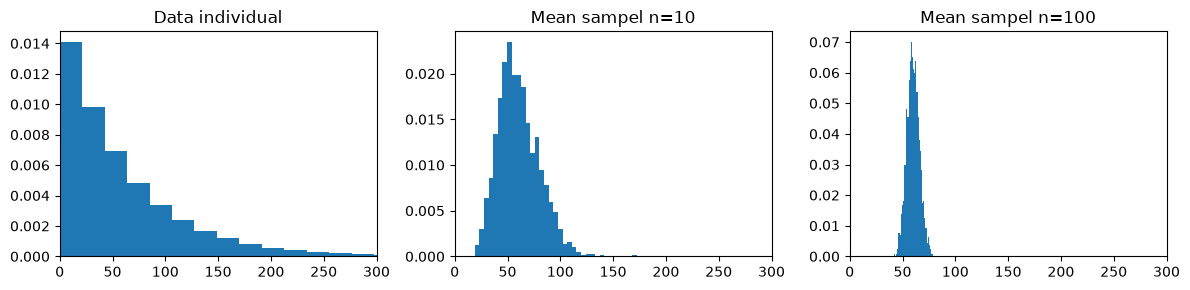

SD mean n=10: 19.32 n=100: 5.96


In [3]:
means_10 = np.array([rng.choice(population, 10).mean() for _ in range(1500)])
means_100 = np.array([rng.choice(population, 100).mean() for _ in range(1500)])
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, values, title in zip(axes, [population, means_10, means_100],
                              ['Data individual', 'Mean sampel n=10', 'Mean sampel n=100']):
    ax.hist(values, bins=35, density=True); ax.set_title(title); ax.set_xlim(0, 300)
plt.tight_layout(); plt.show()
print('SD mean n=10:', round(means_10.std(ddof=1), 2), 'n=100:', round(means_100.std(ddof=1), 2))

## 3. Bootstrap dan interval kepercayaan

Bootstrap mengambil sampel **dengan pengembalian dari sampel yang tersedia**, lalu menghitung ulang statistik. Persentil 2,5 dan 97,5 dari statistik bootstrap membentuk interval persentil 95%. Interpretasi frequentist: prosedur interval akan mencakup parameter sejati kira-kira 95% kali dalam pengulangan eksperimen yang memenuhi asumsi. Bukan berarti ada peluang 95% parameter tetap itu berada dalam interval yang sudah dihitung. Bootstrap tidak menghilangkan bias pada sampel awal.

In [4]:
sample = rng.choice(population, size=200, replace=False)
boot_means = np.array([rng.choice(sample, len(sample), replace=True).mean() for _ in range(4000)])
ci = np.quantile(boot_means, [.025, .975])
print('Mean sampel:', round(sample.mean(), 2))
print('Bootstrap SE:', round(boot_means.std(ddof=1), 2))
print('95% percentile CI:', ci.round(2))
assert ci[0] < sample.mean() < ci[1]

Mean sampel: 61.34
Bootstrap SE: 4.83
95% percentile CI: [52.02 70.88]


## 4. Distribusi teoritis dan QQ plot

Normal memiliki bentuk simetris; distribusi $t$ berekor lebih tebal (khususnya df kecil), relevan untuk inferensi mean dengan varians tak diketahui. QQ plot membandingkan kuantil data dengan normal teoretis. Titik yang membelok dari garis, terutama di ekor, menunjukkan bahwa normalitas mungkin tidak cocok. Uji/plot tidak menggantikan pengetahuan mekanisme data.

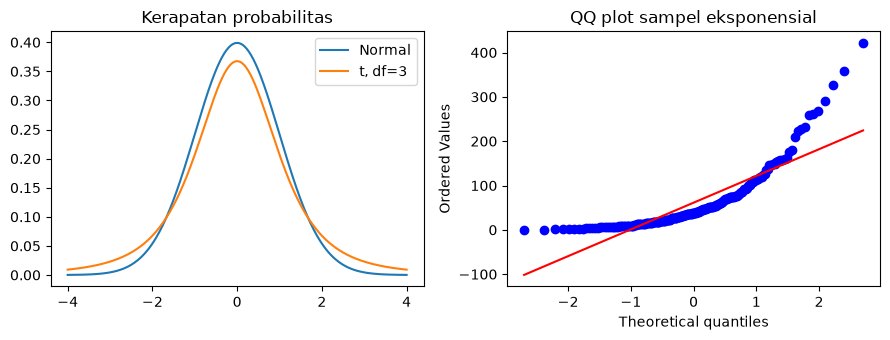

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
z = np.linspace(-4, 4, 300)
axes[0].plot(z, stats.norm.pdf(z), label='Normal')
axes[0].plot(z, stats.t.pdf(z, df=3), label='t, df=3')
axes[0].legend(); axes[0].set_title('Kerapatan probabilitas')
stats.probplot(sample, dist='norm', plot=axes[1]); axes[1].set_title('QQ plot sampel eksponensial')
plt.tight_layout(); plt.show()

## 5. Binomial, chi-square, F, Poisson, eksponensial, Weibull

Binomial menghitung keberhasilan dalam $n$ percobaan Bernoulli independen dengan peluang tetap $p$. Poisson memodelkan hitungan per interval dengan laju tetap; eksponensial memodelkan waktu tunggu antarperistiwa Poisson. Weibull memperluas model waktu tunggu dengan hazard yang bisa berubah. Chi-square dan F banyak muncul sebagai distribusi statistik uji; pilihan model selalu membutuhkan pemeriksaan asumsi.

In [6]:
summary = pd.DataFrame({
    'distribution': ['Binomial n=20,p=.3', 'Poisson mu=3', 'Exponential scale=2', 'Weibull shape=1.5'],
    'illustrative_mean': [rng.binomial(20, .3, 10000).mean(), rng.poisson(3, 10000).mean(),
                          rng.exponential(2, 10000).mean(),
                          (2 * rng.weibull(1.5, 10000)).mean()],
})
print(summary.round(3).to_string(index=False))
print('P(X >= 8), X~Binomial(20,.3):', round(stats.binom.sf(7, 20, .3), 4))
print('95% quantile chi-square(df=4):', round(stats.chi2.ppf(.95, 4), 3))
print('95% quantile F(df1=3, df2=20):', round(stats.f.ppf(.95, 3, 20), 3))

       distribution  illustrative_mean
 Binomial n=20,p=.3              5.999
       Poisson mu=3              2.988
Exponential scale=2              1.990
  Weibull shape=1.5              1.841
P(X >= 8), X~Binomial(20,.3): 0.2277
95% quantile chi-square(df=4): 9.488
95% quantile F(df1=3, df2=20): 3.098


### Ringkasan dan refleksi

- Representativitas ditentukan oleh desain sampling, bukan ukuran sampel saja.
- Standard error mengecil saat ukuran sampel bertambah, tetapi hanya menangani ketidakpastian sampling.
- Bootstrap berguna untuk statistik yang distribusi sampling-nya rumit; tetap harus menghormati struktur data (misalnya data berkelompok/time series).
- Distribusi probabilitas adalah model bersyarat pada asumsi, bukan label otomatis untuk semua data.